In [24]:
# Importing required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [25]:
df = pd.read_csv('StudentPerformanceFactors.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [26]:
# 1. Dataset information
print("DATASET INFORMATION")
print("-" * 40)

df.info()

# 2. Number of rows and columns
print("\nDataset Shape:", df.shape)

# 3. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 4. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 5. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null  

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Duplicate Records: 0


In [27]:
required_columns = [
    'Hours_Studied',
    'Attendance',
    'Previous_Scores',
    'Exam_Score'
]

print("Required columns availability:")

for column in required_columns:
    print(column, ":", column in df.columns)

Required columns availability:
Hours_Studied : True
Attendance : True
Previous_Scores : True
Exam_Score : True


In [28]:
# Create a copy of the original dataset
df_clean = df.copy()

# Check initial dataset size
print("Original Dataset Shape:", df_clean.shape)

# Remove duplicate records
df_clean.drop_duplicates(inplace=True)

# Remove rows where target variable is missing
df_clean.dropna(subset=['Exam_Score'], inplace=True)

# Separate numerical and categorical columns
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

categorical_cols = df_clean.select_dtypes(
    include='object'
).columns

# Fill missing numerical values with median
for col in numeric_cols:
    if col != 'Exam_Score':
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

# Fill missing categorical values with mode
for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

print("\nData Cleaning Completed!")
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum().sum())

print("\nRemaining Duplicate Records:")
print(df_clean.duplicated().sum())

Original Dataset Shape: (6607, 20)

Data Cleaning Completed!
Cleaned Dataset Shape: (6607, 20)

Remaining Missing Values:
0

Remaining Duplicate Records:
0


In [29]:
# Descriptive Statistics

important_features = [
    'Hours_Studied',
    'Attendance',
    'Previous_Scores',
    'Exam_Score'
]

statistics = df_clean[important_features].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

display(statistics)

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
mean,19.975329,79.977448,75.070531,67.235659
median,20.000000,80.000000,75.000000,67.000000
std,5.990594,11.547475,14.399784,3.890456
min,1.000000,60.000000,50.000000,55.000000
max,44.000000,100.000000,100.000000,101.000000


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)

print("Visualization libraries ready!")

Visualization libraries ready!


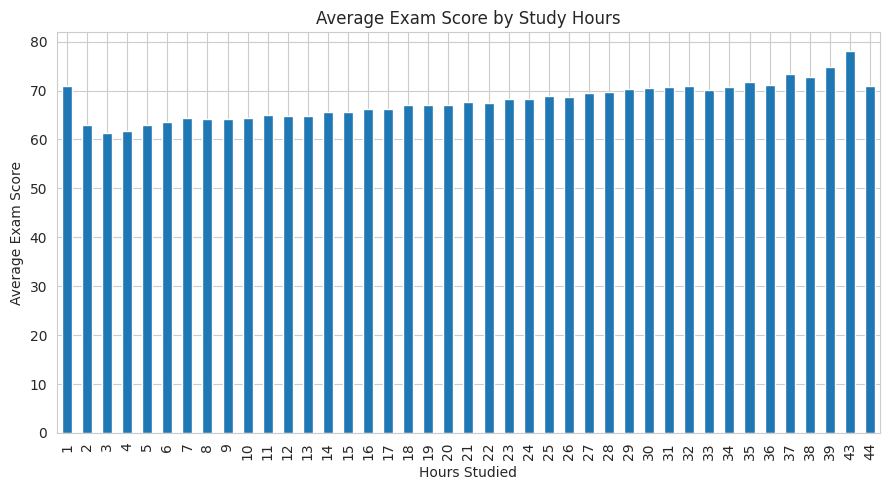

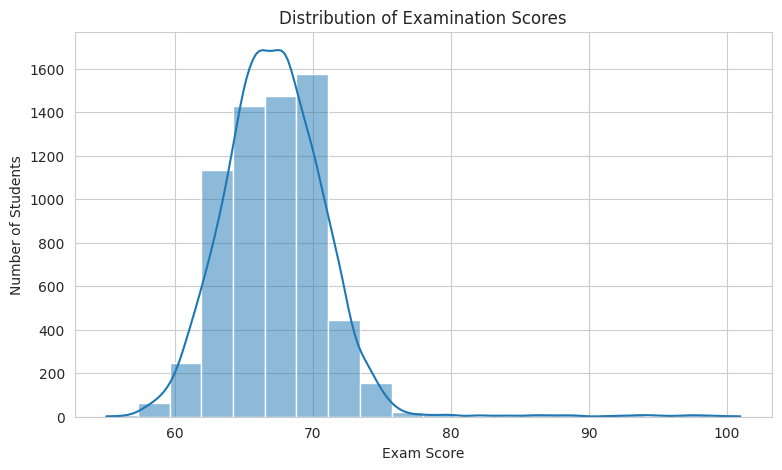

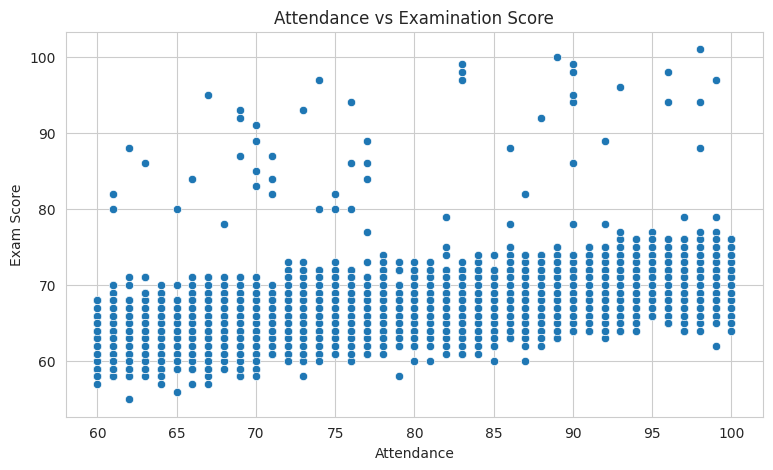

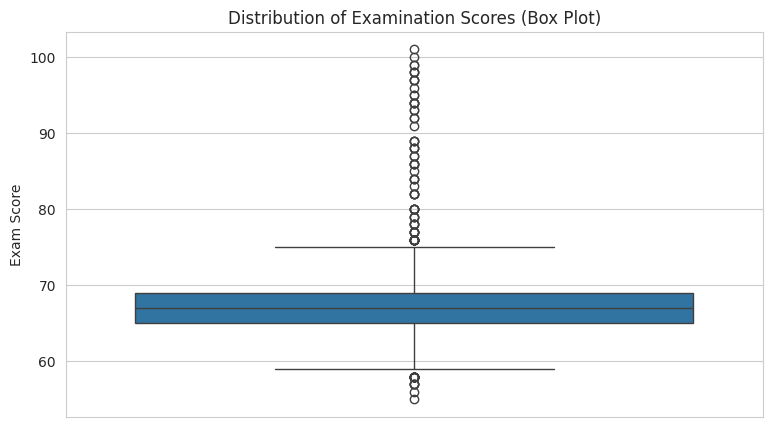

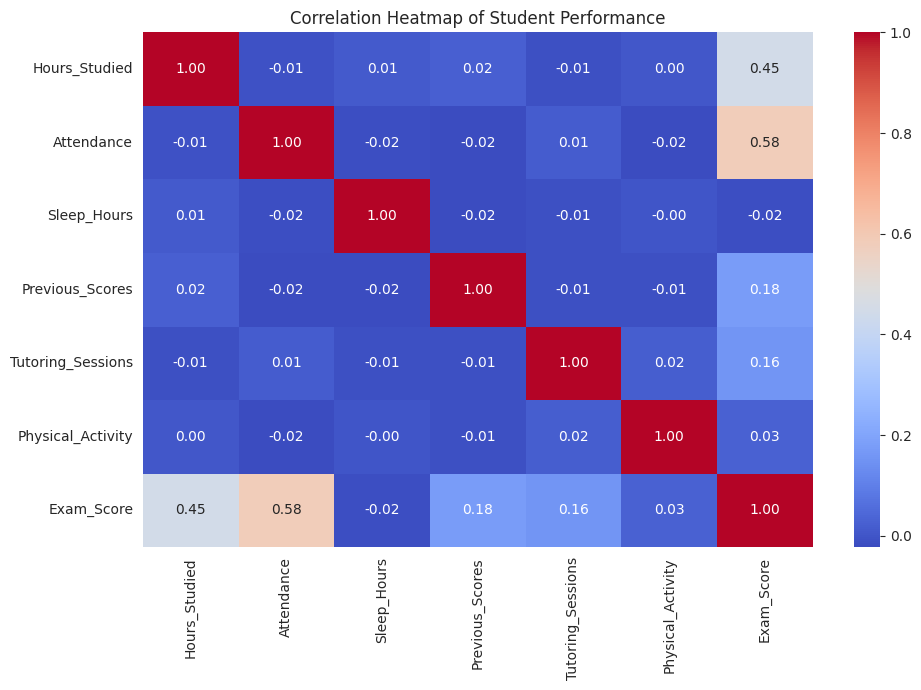

In [31]:
# 1. BAR CHART
plt.figure(figsize=(9, 5))

avg_marks = df_clean.groupby(
    'Hours_Studied'
)['Exam_Score'].mean()

avg_marks.plot(kind='bar')

plt.title('Average Exam Score by Study Hours')
plt.xlabel('Hours Studied')
plt.ylabel('Average Exam Score')
plt.tight_layout()
plt.show()


# 2. HISTOGRAM
plt.figure(figsize=(9, 5))

sns.histplot(
    df_clean['Exam_Score'],
    bins=20,
    kde=True
)

plt.title('Distribution of Examination Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.show()


# 3. SCATTER PLOT
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x='Attendance',
    y='Exam_Score'
)

plt.title('Attendance vs Examination Score')
plt.xlabel('Attendance')
plt.ylabel('Exam Score')
plt.show()


# 4. BOX PLOT
plt.figure(figsize=(9, 5))

sns.boxplot(y=df_clean['Exam_Score'])

plt.title('Distribution of Examination Scores (Box Plot)')
plt.ylabel('Exam Score')
plt.show()


# 5. CORRELATION HEATMAP
plt.figure(figsize=(10, 7))

correlation = df_clean.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Student Performance')
plt.tight_layout()
plt.show()

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


In [33]:
# Input features
X = df_clean[
    ['Hours_Studied', 'Attendance', 'Previous_Scores']
]

# Target variable
y = df_clean['Exam_Score']

print("Input Features:", X.columns.tolist())
print("Target Variable:", y.name)
print("Total Records:", len(X))

Input Features: ['Hours_Studied', 'Attendance', 'Previous_Scores']
Target Variable: Exam_Score
Total Records: 6607


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 5285
Testing Records: 1322


In [35]:
# Create a machine learning pipeline
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [36]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred
})

display(results.head(10))

,Actual Marks,Predicted Marks
0,65,66.024226
1,65,67.121322
2,71,68.680647
3,64,67.422149
4,66,65.098357
5,66,67.762408
6,72,70.550541
7,66,68.101736
8,70,69.778943
9,70,68.932226


In [37]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MODEL EVALUATION RESULTS
-----------------------------------
Mean Absolute Error (MAE): 1.36
Root Mean Squared Error (RMSE): 2.31
R2 Score: 0.6223


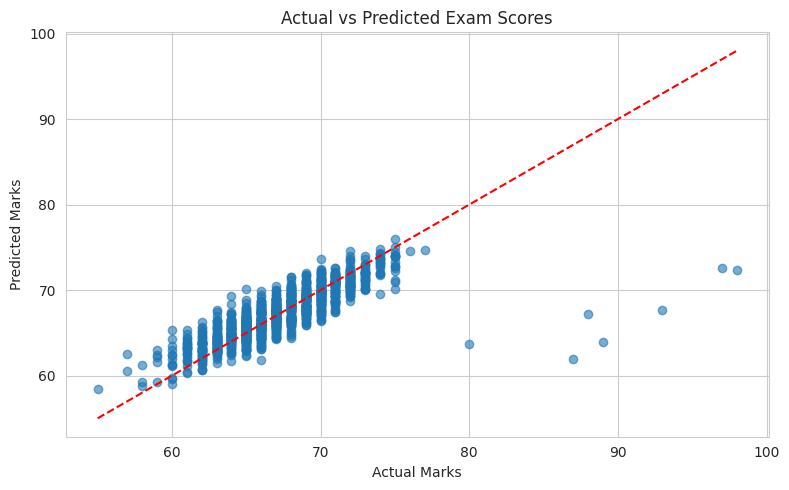

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted Exam Scores')
plt.xlabel('Actual Marks')
plt.ylabel('Predicted Marks')
plt.tight_layout()
plt.show()

In [39]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("R2 Scores:", cv_scores)
print("Average Cross-Validation R2:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

R2 Scores: [0.49618708 0.56713188 0.56557917 0.56999206 0.66518915]
Average Cross-Validation R2: 0.5728
Standard Deviation: 0.0538


In [40]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.named_steps['regressor'].coef_
})

display(coefficients.sort_values(
    by='Coefficient',
    ascending=False
))

,Feature,Coefficient
0,Hours_Studied,0.287498
1,Attendance,0.199134
2,Previous_Scores,0.047464


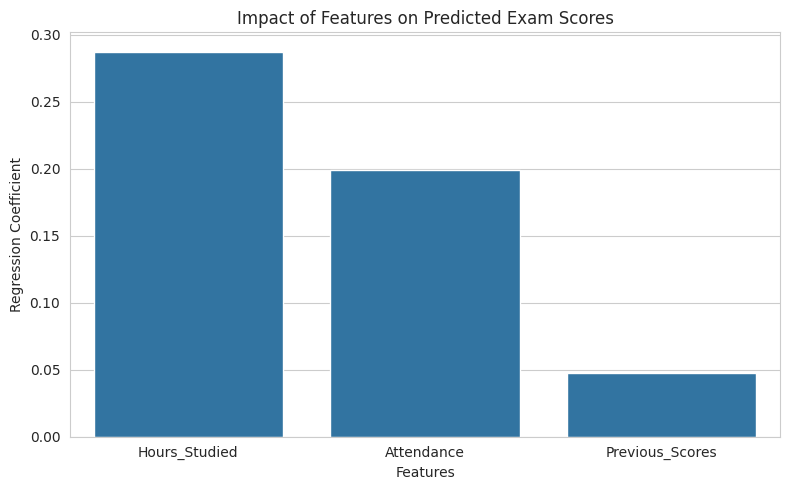

In [41]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=coefficients,
    x='Feature',
    y='Coefficient'
)

plt.title('Impact of Features on Predicted Exam Scores')
plt.xlabel('Features')
plt.ylabel('Regression Coefficient')
plt.tight_layout()
plt.show()

In [42]:
import os

# Create output folders
os.makedirs('outputs/evaluation_results', exist_ok=True)

# Save actual vs predicted values
results.to_csv(
    'outputs/evaluation_results/prediction_results.csv',
    index=False
)

# Save evaluation metrics
evaluation = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score', 'Average CV R2'],
    'Value': [
        mae,
        rmse,
        r2,
        cv_scores.mean()
    ]
})

display(evaluation)

evaluation.to_csv(
    'outputs/evaluation_results/model_evaluation.csv',
    index=False
)

print("Evaluation results saved successfully!")


,Metric,Value
0,MAE,1.359207
1,RMSE,2.310471
2,R2 Score,0.622338
3,Average CV R2,0.572816


Evaluation results saved successfully!


In [43]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('outputs/visualizations', exist_ok=True)

# 1. Average marks by study hours
plt.figure(figsize=(9, 5))
avg_marks = df_clean.groupby('Hours_Studied')['Exam_Score'].mean()
avg_marks.plot(kind='bar')
plt.title('Average Exam Score by Study Hours')
plt.xlabel('Hours Studied')
plt.ylabel('Average Exam Score')
plt.tight_layout()
plt.savefig('outputs/visualizations/study_hours.png')
plt.close()

# 2. Exam score distribution
plt.figure(figsize=(9, 5))
sns.histplot(df_clean['Exam_Score'], bins=20, kde=True)
plt.title('Distribution of Examination Scores')
plt.tight_layout()
plt.savefig('outputs/visualizations/score_distribution.png')
plt.close()

# 3. Attendance vs exam score
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x='Attendance', y='Exam_Score')
plt.title('Attendance vs Examination Score')
plt.tight_layout()
plt.savefig('outputs/visualizations/attendance_vs_score.png')
plt.close()

# 4. Exam score box plot
plt.figure(figsize=(9, 5))
sns.boxplot(y=df_clean['Exam_Score'])
plt.title('Exam Score Box Plot')
plt.tight_layout()
plt.savefig('outputs/visualizations/score_boxplot.png')
plt.close()

# 5. Correlation heatmap
plt.figure(figsize=(12, 8))
correlation = df_clean.select_dtypes(include=np.number).corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('outputs/visualizations/correlation_heatmap.png')
plt.close()

# 6. Actual vs predicted
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.title('Actual vs Predicted Exam Scores')
plt.xlabel('Actual Marks')
plt.ylabel('Predicted Marks')
plt.tight_layout()
plt.savefig('outputs/visualizations/actual_vs_predicted.png')
plt.close()

# 7. Feature coefficients
plt.figure(figsize=(8, 5))
sns.barplot(data=coefficients, x='Feature', y='Coefficient')
plt.title('Feature Coefficients')
plt.tight_layout()
plt.savefig('outputs/visualizations/feature_coefficients.png')
plt.close()

print("All 7 visualizations saved successfully!")

All 7 visualizations saved successfully!


In [44]:
import shutil
from google.colab import files

# Create ZIP file containing all outputs
shutil.make_archive(
    'student_performance_outputs',
    'zip',
    'outputs'
)

# Download ZIP file
files.download('student_performance_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>